In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

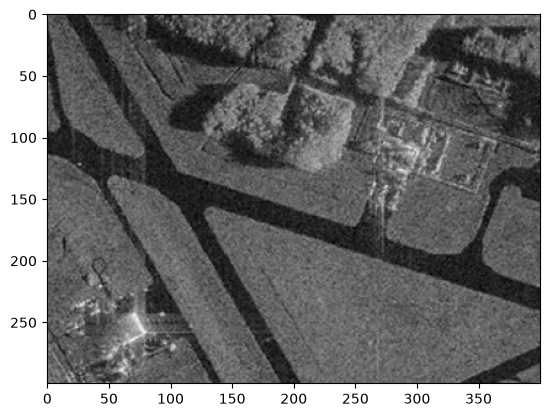

In [3]:
plt.imshow(image_gray, cmap="gray")

In [4]:
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [5]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

In [6]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
        
    return mask*255
    

In [7]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average, 7, 20)

183
526
849
1181
1509
1836
1553
1546
1458
1333
1283
1127
991
981
1035
1088
930
990
842
732
491
553
727
851
912
1086
1308
1461
1670
2112
1863
1801
2017
2144
2475
2427
2667
1756
1767
1825
1414
1033
1014
1043
1387
1575
1569
1519
1704
1230
635
547
483
448
506
401
318
167
157
165
7
0


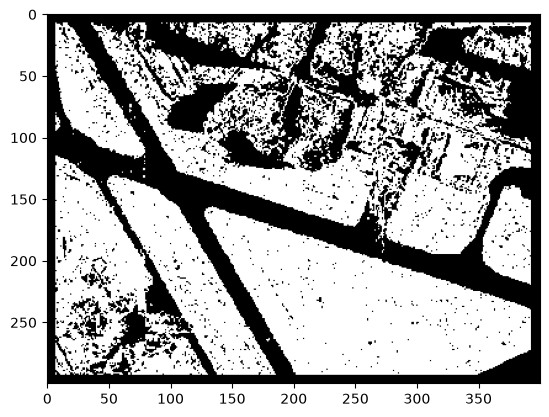

In [8]:
plt.imshow(mask, cmap="gray")

In [9]:
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

183
532
842
1193
1520
1849
1520
1550
1506
1345
1229
1128
991
982
1043
1088
1052
875
850
750
592
676
799
960
1059
1294
1491
1835
1712
1931
1744
1838
2193
2481
2529
2197
2130
1756
1741
1826
1465
989
1008
1248
1411
1500
1392
1682
1508
685
577
1405
561
539
481
393
327
162
179
0


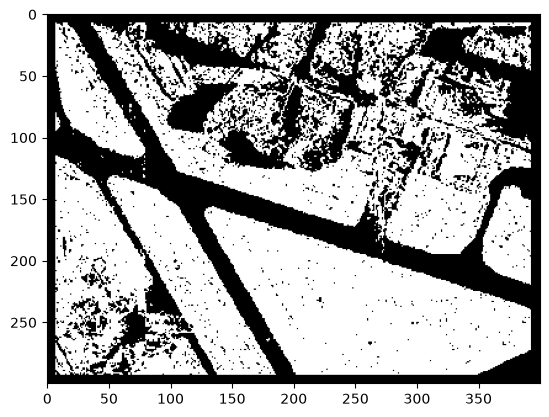

In [10]:
def homo_median(img, mask, point, T):
    median = np.median(img[mask > 0])
    return abs(median - img[point]) <= T

mask_median = region_growing(image_gray, seed_point, homo_median, 7, 20)
plt.imshow(mask_median, cmap="gray")

In [11]:
from skimage.transform import resize
import numpy as np
from skimage.metrics import structural_similarity, mean_squared_error

mask = resize(mask, image_gray.shape, order=0,
              preserve_range=True, anti_aliasing=False).astype(np.uint8)

mse_average = mean_squared_error(image_gray, mask)
mse_median  = mean_squared_error(image_gray, mask_median)
ssim_average, _ = structural_similarity(image_gray, mask,        data_range=255, full=True)
ssim_median,  _ = structural_similarity(image_gray, mask_median, data_range=255, full=True)

print(mse_average, ssim_average)
print(mse_median, ssim_median)

16800.3512 0.11734194367594301
16997.2622 0.12257202165724353


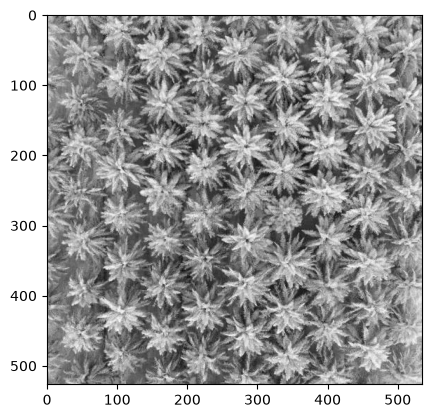

In [12]:
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

image = cv2.imread('palm_1.JPG')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

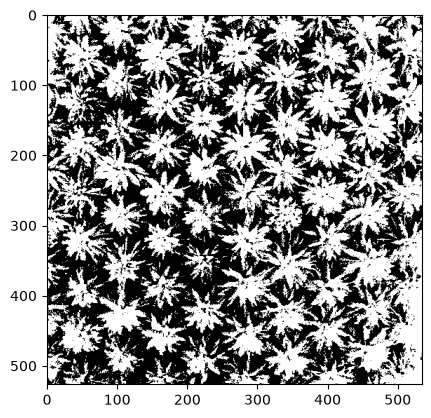

In [13]:
ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.imshow(thresh, cmap="gray")

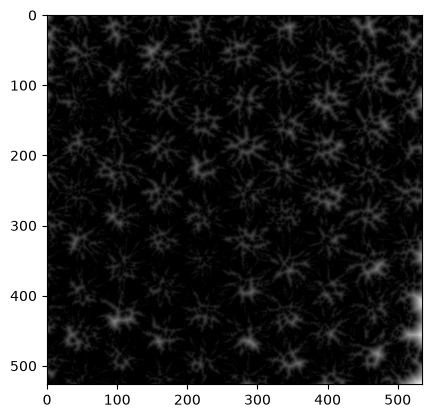

In [14]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

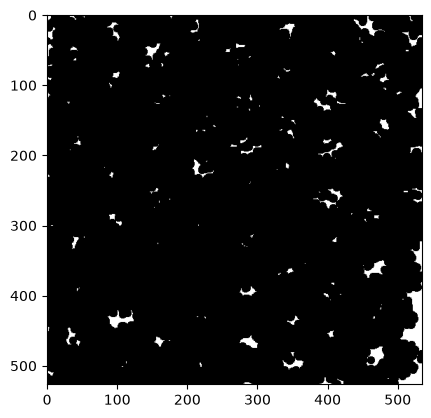

In [23]:
ret, sure_fg = cv2.threshold(dist, 0.25 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

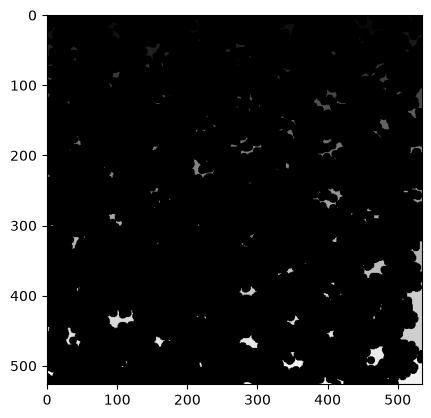

In [24]:
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
plt.imshow(markers, cmap="gray")

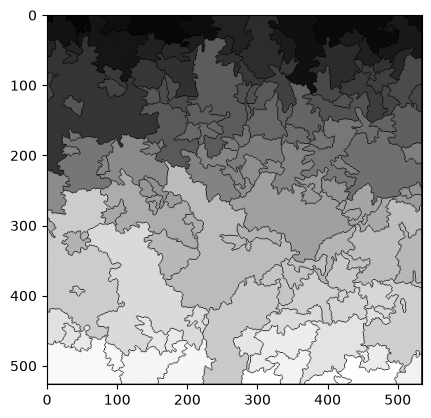

In [25]:
markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

In [26]:
count = len(np.unique(markers)) - 1
print(f"Количество деревьев: {count}")

Количество деревьев: 167
